
QUESTION 3.1 – RESEARCH ARTICLES
Number of articles: 5
                          Article
0  research_corpus/research_1.txt
1  research_corpus/research_2.txt
2  research_corpus/research_3.txt
3  research_corpus/research_4.txt
4  research_corpus/research_5.txt

Dataframe shape: (5, 2)

First article content:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixe

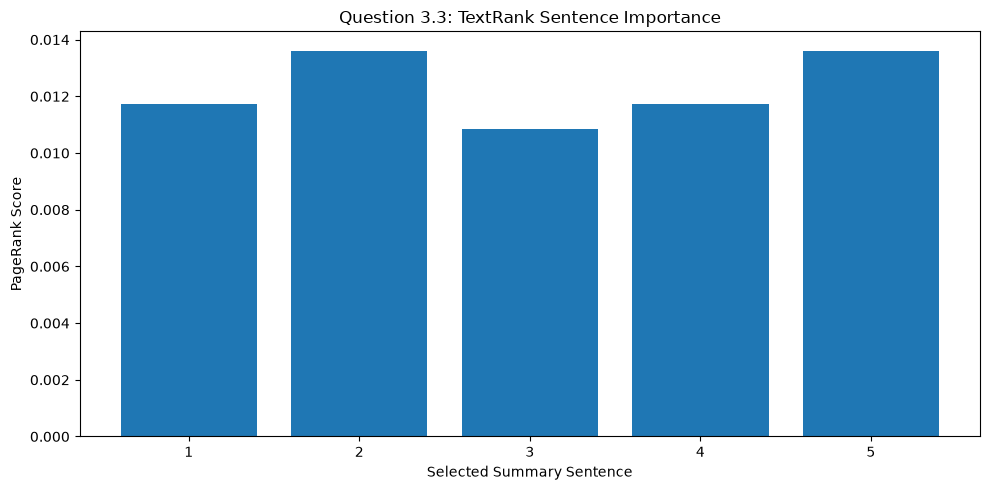


QUESTION 3.4 – AGGREGATED LSA SUMMARY
- Cronbach’s alpha is regularly adopted in studies in science education: it was referred to in 69 different papers published in 4 leading science education journals in a single year (2015)—usually as a measure of reliability.
- The Use of Cronbach’s Alpha in Science Education Studies
It is common to see the reliability of instruments used in published science education studies framed in terms of a statistic known as Cronbach’s alpha (Cronbach, 1951).
- The Frequency of Use of Cronbach’s Alpha in Science Education
To give an indication of the extent to which Cronbach’s alpha is used in science education research, a survey was undertaken of papers published in issues of four prestigious science education journals during one academic year.
- Two other papers (that did not use the terms reliability or internal consistency) did specify that alpha was concerned with items being on a single scale or unidimensionality (as will be discussed later in this a

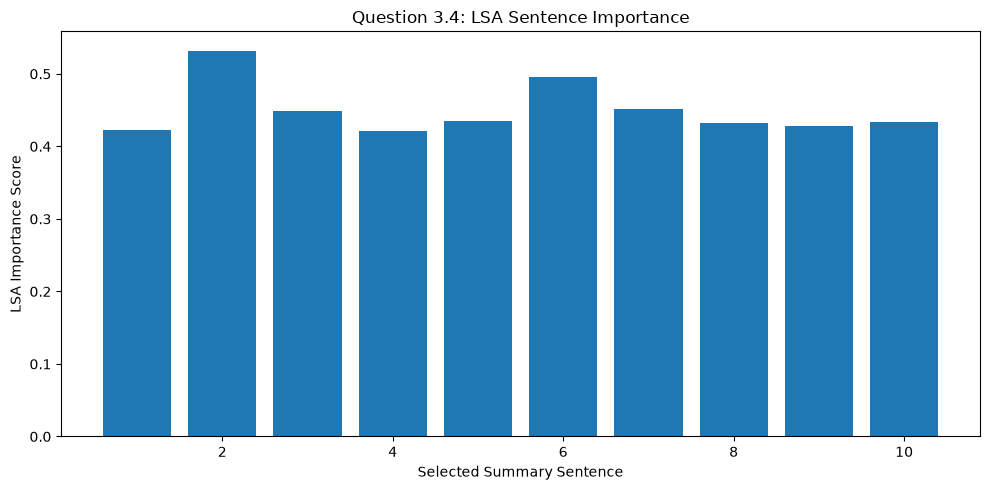

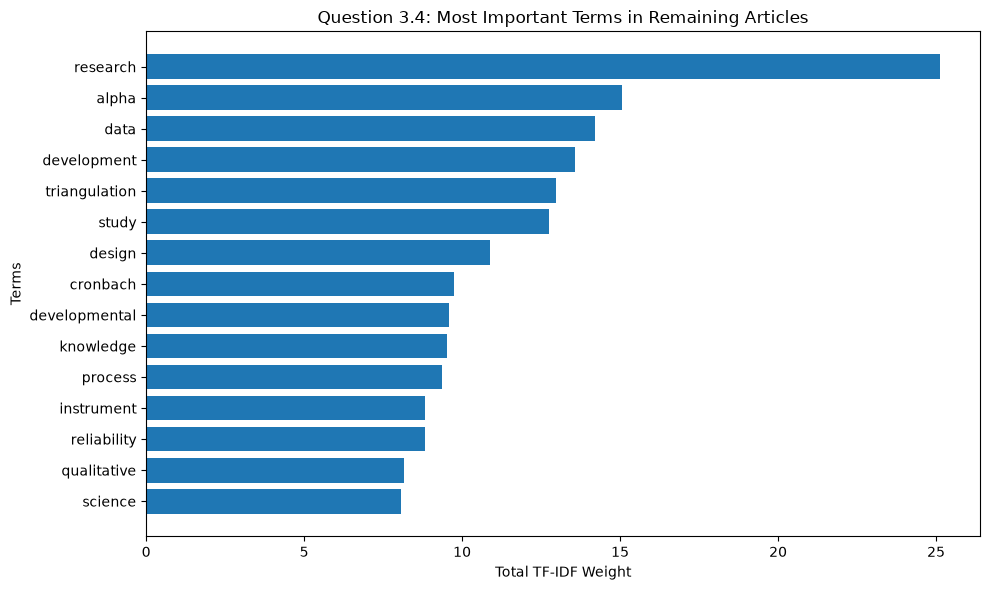

In [1]:
#3.1

import zipfile
import re
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

zip_path = "C:\\Users\\kgour\\OneDrive\\Documents\\School\\ITNP\\Research-Document-Mining\\datasets\\research_corpus.zip"

articles = []

# Read all text files from the ZIP dataset
with zipfile.ZipFile(zip_path, "r") as corpus_zip:

    text_files = [
        name for name in corpus_zip.namelist()
        if name.lower().endswith(".txt")
        and not name.startswith("__MACOSX/")
    ]

    for file_name in text_files:
        content = corpus_zip.read(file_name).decode(
            "utf-8", errors="ignore"
        )

        articles.append({
            "Article": file_name,
            "Content": content
        })


# Create dataframe
df = pd.DataFrame(articles)

print("\nQUESTION 3.1 – RESEARCH ARTICLES")
print("Number of articles:", len(df))
print(df[["Article"]].head())
print("\nDataframe shape:", df.shape)
print("\nFirst article content:")
print(df["Content"].iloc[0][:1000])


#3.2

def preprocess_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove DOI references
    text = re.sub(r"\b10\.\d{4,9}/\S+", " ", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove common English stop words
    words = [
        word for word in text.split()
        if word not in ENGLISH_STOP_WORDS and len(word) > 2
    ]

    return " ".join(words)


# Apply preprocessing to every article
df["Cleaned_Content"] = df["Content"].apply(preprocess_text)

print("\nQUESTION 3.2 – PREPROCESSING RESULTS")
print("Original article count:", len(df))
print("Missing cleaned articles:", df["Cleaned_Content"].isna().sum())
print("\nFirst cleaned article:")
print(df["Cleaned_Content"].iloc[0][:1000])


#3.3

def textrank_summary(text, number_of_sentences=5):

    # Split article into sentences
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())

    sentences = [
        sentence.strip()
        for sentence in sentences
        if len(sentence.split()) > 5
    ]

    if len(sentences) <= number_of_sentences:
        return sentences, [1.0] * len(sentences)

    # Convert sentences into TF-IDF vectors
    vectorizer = TfidfVectorizer(stop_words="english")
    sentence_vectors = vectorizer.fit_transform(sentences)

    # Calculate sentence similarity
    similarity_matrix = cosine_similarity(sentence_vectors)

    # Build similarity graph
    graph = nx.from_numpy_array(similarity_matrix)

    # Apply PageRank to rank sentences
    scores = nx.pagerank(graph)

    # Rank sentences by importance
    ranked_sentences = sorted(
        scores, key=scores.get, reverse=True
    )

    # Select the highest-ranked sentences
    selected_indices = sorted(
        ranked_sentences[:number_of_sentences]
    )

    summary = [sentences[i] for i in selected_indices]
    selected_scores = [scores[i] for i in selected_indices]

    return summary, selected_scores


# Summarise first article
first_article = df["Content"].iloc[0]

summary_1, scores_1 = textrank_summary(
    first_article, number_of_sentences=5
)

print("\nQUESTION 3.3 – TEXTRANK SUMMARY")
for sentence in summary_1:
    print("-", sentence)


# Visualise TextRank sentence importance
plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(scores_1) + 1),
    scores_1
)

plt.title("Question 3.3: TextRank Sentence Importance")
plt.xlabel("Selected Summary Sentence")
plt.ylabel("PageRank Score")
plt.tight_layout()
plt.show()


#3.4

# Select all articles except the first
remaining_articles = df["Content"].iloc[1:]

# Combine remaining articles into one corpus
combined_text = " ".join(remaining_articles)

# Split combined corpus into sentences
sentences = re.split(r"(?<=[.!?])\s+", combined_text)

sentences = [
    sentence.strip()
    for sentence in sentences
    if len(sentence.split()) > 5
]

# Create TF-IDF sentence matrix
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

sentence_matrix = vectorizer.fit_transform(sentences)

# Apply Latent Semantic Analysis
n_components = min(
    2,
    sentence_matrix.shape[0] - 1,
    sentence_matrix.shape[1] - 1
)

if n_components >= 1:

    svd = TruncatedSVD(
        n_components=n_components,
        random_state=42
    )

    sentence_vectors = svd.fit_transform(sentence_matrix)

    # Rank sentences using their latent representation
    sentence_scores = (
        sentence_vectors ** 2
    ).sum(axis=1) ** 0.5

    # Select the most important sentences
    top_indices = sentence_scores.argsort()[-10:]

    top_indices = sorted(top_indices)

    summary_2 = [sentences[i] for i in top_indices]

    print("\nQUESTION 3.4 – AGGREGATED LSA SUMMARY")

    for sentence in summary_2:
        print("-", sentence)

    # Visualise sentence importance
    plt.figure(figsize=(10, 5))

    plt.bar(
        range(1, len(top_indices) + 1),
        sentence_scores[top_indices]
    )

    plt.title("Question 3.4: LSA Sentence Importance")
    plt.xlabel("Selected Summary Sentence")
    plt.ylabel("LSA Importance Score")
    plt.tight_layout()
    plt.show()

else:
    print("Not enough text to perform LSA summarisation.")


# Visualise the most important terms across remaining articles
term_scores = sentence_matrix.sum(axis=0).A1
terms = vectorizer.get_feature_names_out()

top_term_indices = term_scores.argsort()[-15:][::-1]

plt.figure(figsize=(10, 6))

plt.barh(
    terms[top_term_indices][::-1],
    term_scores[top_term_indices][::-1]
)

plt.title("Question 3.4: Most Important Terms in Remaining Articles")
plt.xlabel("Total TF-IDF Weight")
plt.ylabel("Terms")
plt.tight_layout()
plt.show()

